# Part 3: Data quality in weather and reservoir filling

This notebook prepares eight reproducible weather locations and demonstrates
DCT/SPC, Local Outlier Factor (LOF), STL, and a spectrogram. The notebook and
Streamlit app import the same analysis functions; visible checks accompany each
step. The demonstration uses **NO3 weather in 2024** and **all available NO3
weekly filling history**.

In [3]:
from pathlib import Path
import logging
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from ind320.config import ROOT
from ind320.data.areas import load_weather_areas, sample_weather_points
from ind320.data.weather import fetch_weather, daily_weather, load_weather_coordinates
from ind320.data.reservoirs import fetch_reservoir_history
from ind320.analysis.weather import precipitation_analysis, temperature_analysis
from ind320.analysis.reservoirs import weekly_filling, stl_analysis, filling_spectrogram

2026-11-07 12:25:35.385 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-11-07 12:25:35.386 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


## Area definitions and reproducible sampling

`Budomraader/` supplies NO1-NO5 electricity-area polygons. `NVE_Region/` supplies
five administrative regions. East combines **RS + RØ**, West uses **RV**, and
North combines **RM + RN**. These three groups approximate precipitation areas;
they are **not exact catchment boundaries** or exact VASS boundaries. We do not
compare the grouped weather polygons numerically with VASS areas here. NO3
weather and EL 3 filling share an electricity-area label, but one weather point
still cannot represent precipitation over the whole area.

In [4]:
# Prepare all eight polygons, sample candidates, and save the chosen API coordinates.
areas = load_weather_areas()
candidates, chosen = sample_weather_points(areas, count=1000, seed=320)
coordinates = chosen.assign(
    latitude=chosen.geometry.y, longitude=chosen.geometry.x
)[["area", "latitude", "longitude"]]
(ROOT / "data").mkdir(exist_ok=True)
coordinate_path = ROOT / "data" / "weather_coordinates.csv"
coordinates.to_csv(coordinate_path, index=False, float_format="%.8f")
display(coordinates.round(5))

,area,latitude,longitude
0,NO1,59.83469,10.58618
1,NO2,59.22612,6.69521
2,NO3,61.43172,5.41610
3,NO4,67.82270,15.99120
4,NO5,60.38271,4.55572
5,East,60.09849,10.11488
6,West,62.86050,7.28856
7,North,62.54329,11.58147


In [5]:
# Visible sampling checks: counts, containment, deterministic reruns, and CSV contents.
assert len(areas) == 8 and areas.geometry.is_valid.all()
assert candidates.groupby("area").size().eq(1000).all()
projected_candidates = candidates.to_crs(areas.crs)
projected_chosen = chosen.to_crs(areas.crs)
for area, polygon in areas.geometry.items():
    assert projected_candidates.loc[candidates["area"] == area].within(polygon).all()
    assert projected_chosen.loc[chosen["area"] == area].within(polygon).all()
_, repeated = sample_weather_points(areas, count=1000, seed=320)
assert chosen.equals(repeated)
saved = load_weather_coordinates()
assert len(saved) == 8 and saved.index.is_unique
assert set(saved.index) == set(areas.index)
assert np.allclose(saved[["latitude", "longitude"]], coordinates[["latitude", "longitude"]])
print("PASS: 1,000 interior points per area; eight reproducible coordinates saved.")

PASS: 1,000 interior points per area; eight reproducible coordinates saved.


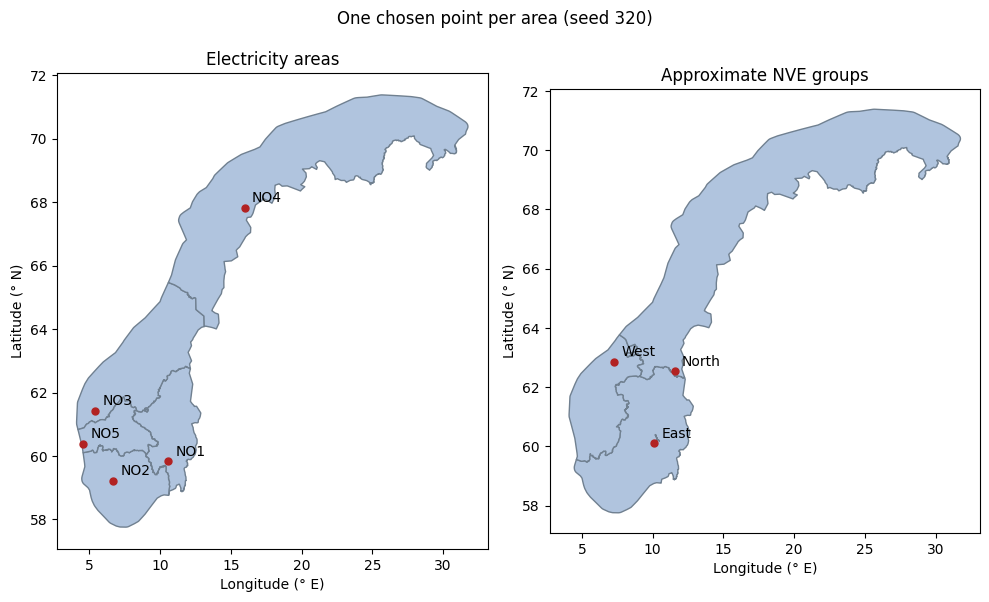

In [6]:
# Show both area systems separately because their polygons overlap one another.
fig, axes = plt.subplots(1, 2, figsize=(10, 6))
for ax, names, title in zip(
    axes, [list(areas.index[:5]), list(areas.index[5:])],
    ["Electricity areas", "Approximate NVE groups"]
):
    areas.loc[names].to_crs(4326).plot(ax=ax, color="lightsteelblue", edgecolor="slategray")
    chosen.loc[chosen["area"].isin(names)].plot(ax=ax, color="firebrick", markersize=25)
    for row in chosen.loc[chosen["area"].isin(names)].itertuples():
        ax.annotate(row.area, (row.geometry.x, row.geometry.y), xytext=(5, 4), textcoords="offset points")
    ax.set(title=title, xlabel="Longitude (° E)", ylabel="Latitude (° N)")
fig.suptitle("One chosen point per area (seed 320)")
fig.tight_layout()
plt.show()

## Hourly ERA5 weather for NO3, 2024

The [Open-Meteo Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api)
provides Copernicus ERA5 reanalysis. We explicitly request `models=era5`,
`precipitation`, `temperature_2m`, and `timezone=UTC` for January 1-December 31,
2024. UTC avoids daylight-saving gaps and duplicated hours. A complete leap year
has **8,784 hours and 366 days**. The downloader checks the complete hourly index
and rejects missing responses rather than silently filling them.

In [8]:
# One chosen coordinate, one full-year request; no candidate-point loop over the API.
hourly = fetch_weather("NO3", "2024-01-01", "2024-12-31")
daily = daily_weather(hourly)
print("Chosen point:", hourly.attrs["latitude"], hourly.attrs["longitude"])
print("ERA5 grid cell:", hourly.attrs["grid_latitude"], hourly.attrs["grid_longitude"])
display(daily.head())

Chosen point: 61.43171828 5.41610441
ERA5 grid cell: 61.5 5.5


,precipitation,temperature_2m
time,,
2024-01-01 00:00:00+00:00,0.012500,-0.716667
2024-01-02 00:00:00+00:00,0.008333,-3.787500
2024-01-03 00:00:00+00:00,0.000000,-7.887500
2024-01-04 00:00:00+00:00,0.000000,-10.083333
2024-01-05 00:00:00+00:00,0.000000,-14.137500


In [9]:
# Check leap-year coverage, UTC, source units, and correct daily averaging.
expected_hours = pd.date_range("2024-01-01", "2024-12-31 23:00", freq="h", tz="UTC")
assert hourly.index.equals(expected_hours) and len(hourly) == 8784
assert str(hourly.index.tz) == "UTC" and len(daily) == 366
assert hourly.notna().all().all() and np.isfinite(hourly.to_numpy()).all()
assert (hourly.precipitation >= 0).all()
assert np.allclose(daily.iloc[0], hourly.iloc[:24].mean())
assert np.allclose(daily.precipitation * 24, hourly.precipitation.resample("D").sum())
print("PASS: 8,784 complete UTC hours and 366 daily averages, including February 29.")

PASS: 8,784 complete UTC hours and 366 daily averages, including February 29.


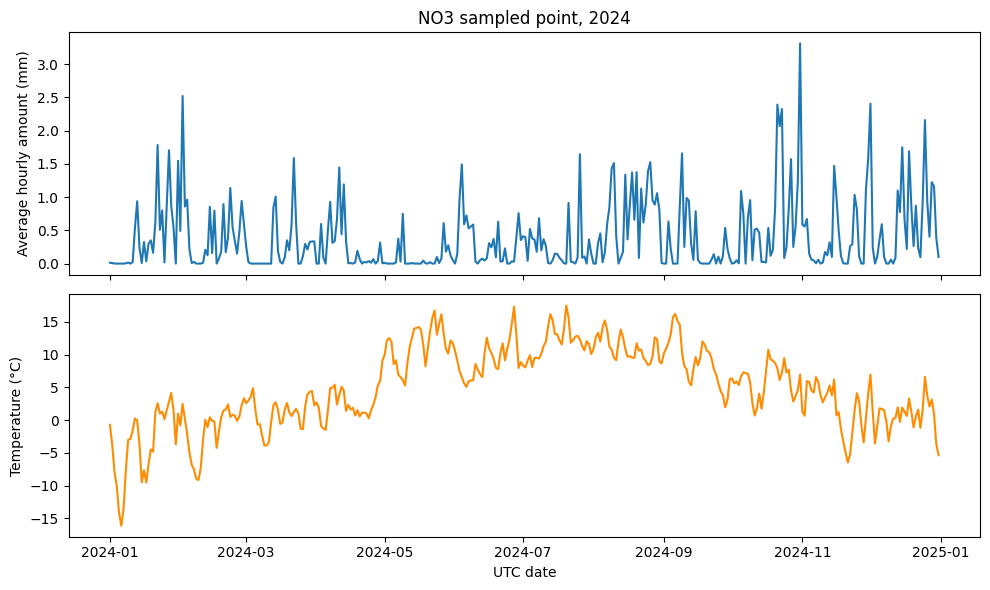

In [10]:
# Daily plots retain distinct units; averaging rainfall amounts is not summing them.
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(daily.index, daily.precipitation)
axes[0].set(title="NO3 sampled point, 2024", ylabel="Average hourly amount (mm)")
axes[1].plot(daily.index, daily.temperature_2m, color="darkorange")
axes[1].set(xlabel="UTC date", ylabel="Temperature (°C)")
fig.tight_layout()
plt.show()

## Precipitation: DCT high-pass filter and robust SPC

The Discrete Cosine Transform (DCT) expresses the daily series as cosine
coefficients from slow to fast variation. We set the first **eight** coefficients
(including the mean) to zero and invert the transform. The remaining signal
emphasizes faster changes. Setting the cutoff to zero returns the original
series. Raising the cutoff removes more slow variation; it is not an exact
calendar-season adjustment. Eight coefficients over 366 days correspond roughly
to removing variations slower than a few months. Boundary effects and the
chosen interval can affect the result.

For robust statistical process control (SPC), calculate the median of the
filtered values and estimate sigma as **1.4826 × MAD**, where MAD is the median
absolute deviation from that median. Flag residuals outside median ± **3 sigma**
over the full selected year. If MAD is zero, the function explicitly falls back
to sample standard deviation. Limits are translated back onto the original
precipitation series so the flagged dates remain interpretable. Filtered amounts
and lower limits may be negative even though rainfall itself is nonnegative.

**Assignment wording conflict:** the task applies DCT to precipitation but calls
its output “seasonally adjusted temperature variations” in one sentence. This
implementation follows the precipitation instruction and labels the filtered
result as precipitation. No temperature interpretation is assigned to it.

Rainfall is skewed and autocorrelated, so these are exploratory SPC flags, not
calibrated normal-tail probabilities or proof of data errors. The cutoff and
multiplier are adjustable in the app.

{'days': 366, 'outliers': 24, 'center': -0.14947965752622902, 'sigma': 0.35351516933458904, 'scale_method': 'normal-scaled MAD'}


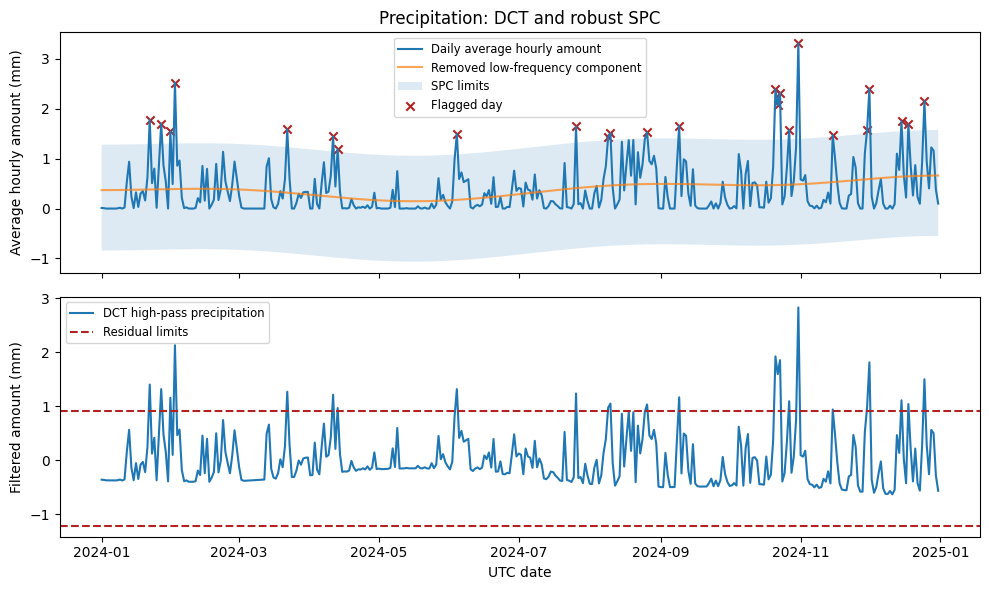

,precipitation,filtered
time,,
2024-01-22 00:00:00+00:00,1.783333,1.401558
2024-01-27 00:00:00+00:00,1.704167,1.317623
2024-01-31 00:00:00+00:00,1.545833,1.155684
2024-02-02 00:00:00+00:00,2.520833,2.129056
2024-03-22 00:00:00+00:00,1.587500,1.268936


In [12]:
# Shared analysis returns plot data, a concise summary, and the same figure used in the app.
precipitation, precipitation_summary, fig = precipitation_analysis(daily.precipitation)
print(precipitation_summary)
plt.show()
display(precipitation.loc[precipitation.outlier, ["precipitation", "filtered"]].head())

DCT/SPC: 3 of 366 days flagged (exploratory flags).


<Figure size 1000x600 with 2 Axes>

                           temperature_2m  baseline   filtered  outlier
time                                                                   
2024-01-05 00:00:00+00:00      -14.137500 -4.514985  -9.622515     True
2024-01-06 00:00:00+00:00      -16.125000 -4.495145 -11.629855     True
2024-01-07 00:00:00+00:00      -13.429167 -4.471421  -8.957745     True

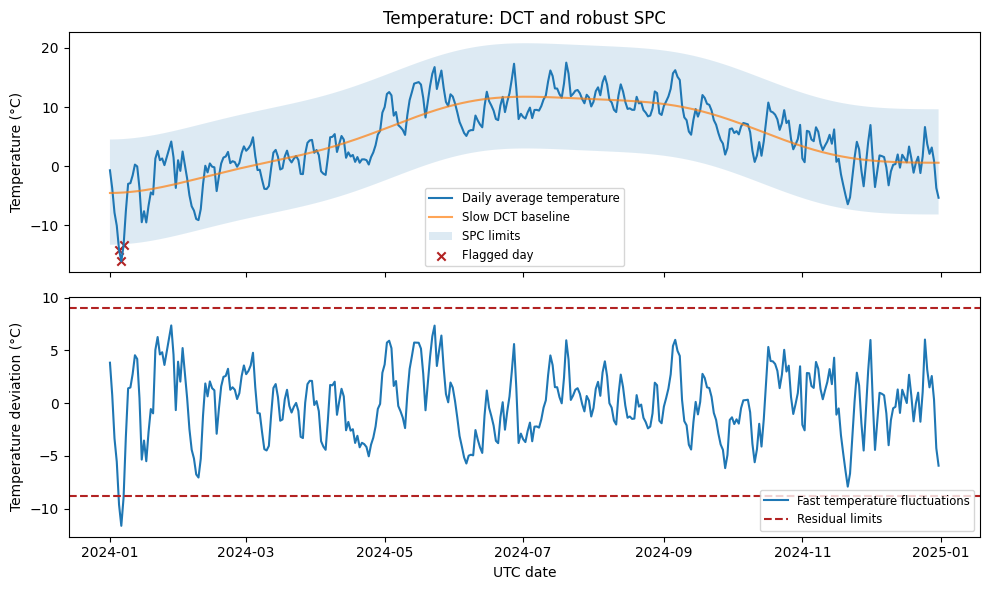

In [ ]:
# Temperature: the same DCT high-pass filter and robust SPC used above.
# This approximates seasonal adjustment; it is separate from temperature LOF below.
from scipy.fft import dct, idct
from scipy.stats import median_abs_deviation

# Remove the mean and seven other slow cosine components from daily temperature.
temperature_values = daily.temperature_2m.to_numpy(dtype=float)
temperature_coefficients = dct(temperature_values, norm="ortho")
temperature_coefficients[:8] = 0
temperature_filtered = idct(temperature_coefficients, norm="ortho")
temperature_baseline = temperature_values - temperature_filtered

# Estimate robust limits on the fluctuations, with the same zero-MAD fallback.
temperature_center = float(np.median(temperature_filtered))
temperature_sigma = float(median_abs_deviation(temperature_filtered, scale="normal"))
if temperature_sigma == 0:
    temperature_sigma = float(np.std(temperature_filtered, ddof=1))
temperature_lower = temperature_center - 3 * temperature_sigma
temperature_upper = temperature_center + 3 * temperature_sigma
temperature_flags = (
    (temperature_filtered < temperature_lower)
    | (temperature_filtered > temperature_upper)
)
temperature_dct = pd.DataFrame(
    {"temperature_2m": temperature_values, "baseline": temperature_baseline,
     "filtered": temperature_filtered, "outlier": temperature_flags},
    index=daily.index,
)

# Translate the residual limits onto the original temperature scale in the top panel.
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(daily.index, temperature_values, label="Daily average temperature")
axes[0].plot(daily.index, temperature_baseline, label="Slow DCT baseline", alpha=0.7)
axes[0].fill_between(
    daily.index, temperature_baseline + temperature_lower,
    temperature_baseline + temperature_upper, alpha=0.15, label="SPC limits",
)
axes[0].scatter(
    daily.index[temperature_flags], temperature_values[temperature_flags],
    color="firebrick", marker="x", label="Flagged day",
)
axes[0].set(title="Temperature: DCT and robust SPC", ylabel="Temperature (°C)")
axes[0].legend(fontsize="small")
axes[1].plot(daily.index, temperature_filtered, label="Fast temperature fluctuations")
axes[1].axhline(temperature_lower, color="firebrick", linestyle="--")
axes[1].axhline(temperature_upper, color="firebrick", linestyle="--", label="Residual limits")
axes[1].set(xlabel="UTC date", ylabel="Temperature deviation (°C)")
axes[1].legend(fontsize="small")
fig.tight_layout()
plt.show()

# Both panels flag the same dates; the components must reconstruct the input.
assert np.allclose(temperature_baseline + temperature_filtered, temperature_values)
assert np.array_equal(
    temperature_flags,
    (temperature_values < temperature_baseline + temperature_lower)
    | (temperature_values > temperature_baseline + temperature_upper),
)
print(f"DCT/SPC: {temperature_flags.sum()} of {len(daily)} days flagged (exploratory flags).")
display(temperature_dct.loc[temperature_dct.outlier])


In [ ]:
# Inspect sensitivity instead of treating defaults as universal weather thresholds.
rows = []
for cutoff in [4, 8, 16]:
    for multiplier in [2.0, 3.0, 4.0]:
        _, summary, check_fig = precipitation_analysis(daily.precipitation, cutoff, multiplier)
        rows.append({"cutoff": cutoff, "multiplier": multiplier, "flagged_days": summary["outliers"]})
        plt.close(check_fig)
display(pd.DataFrame(rows).pivot(index="cutoff", columns="multiplier", values="flagged_days"))
print("Default flags (% of days):", round(100 * precipitation.outlier.mean(), 1))

multiplier,2.0,3.0,4.0
cutoff,,,
4,46,28,12
8,40,24,11
16,51,23,15


Default flags (% of days): 6.6


{'days': 366, 'outliers': 4, 'mean_c': 4.994387522768671, 'contamination': 0.01}


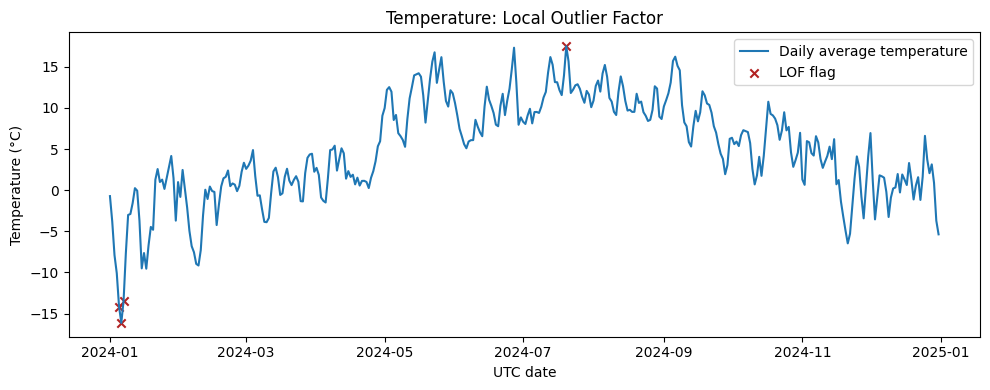

,temperature_2m,lof_score,outlier
time,,,
2024-01-05 00:00:00+00:00,-14.137500,2.355833,True
2024-01-06 00:00:00+00:00,-16.125000,2.871007,True
2024-01-07 00:00:00+00:00,-13.429167,2.207369,True
2024-07-20 00:00:00+00:00,17.508333,1.867584,True


In [ ]:
# Highlight the detected dates on the original temperature timeline.
temperature, temperature_summary, fig = temperature_analysis(daily.temperature_2m)
print(temperature_summary)
plt.show()
display(temperature.loc[temperature.outlier])

In [ ]:
# Check LOF output and the effect of moving the score threshold.
assert temperature.index.equals(daily.index)
assert np.allclose(temperature.temperature_2m, daily.temperature_2m)
assert np.isfinite(temperature.lof_score).all()
assert temperature_summary["outliers"] == int(temperature.outlier.sum())
more_flags, _, check_fig = temperature_analysis(daily.temperature_2m, contamination=0.05)
assert more_flags.outlier.sum() >= temperature.outlier.sum()
assert (more_flags.outlier | ~temperature.outlier).all()
plt.close(check_fig)
print("PASS: original temperatures retained; higher contamination includes the default flags.")

PASS: original temperatures retained; higher contamination includes the default flags.


## Full weekly reservoir history

The [NVE Magasinstatistikk API](https://biapi.nve.no/magasinstatistikk/swagger/index.html)
returns all available filling observations. We select **EL 3 (NO3)**, independently
of the weather year. Fractions are converted to percentages once. Each row in the
series represents one week, not one month or one year.

STL and the spectrogram need equally spaced samples. The shared preparation
function creates a seven-day grid between the first and last available dates.
It interpolates only internal missing weeks in time and reports their count.
It rejects duplicate or off-grid dates rather than silently averaging them.
Interpolation can smooth local variation and must be considered when interpreting
the plots. At least 104 weeks are required for the two annual cycles.

In [18]:
# Use the existing cached public NVE downloader, without any month/year filter.
reservoir_source = fetch_reservoir_history()
weekly = weekly_filling(reservoir_source, "EL", 3)
print(f"NO3 full history: {weekly.index.min():%Y-%m-%d} to {weekly.index.max():%Y-%m-%d}")
print(f"{len(weekly)} weeks; {weekly.attrs['interpolated_weeks']} interpolated weeks.")
assert len(weekly) >= 104 and np.isfinite(weekly).all()
assert (weekly.index.to_series().diff().dropna() == pd.Timedelta(weeks=1)).all()
original = reservoir_source.loc[
    (reservoir_source["Area Type"] == "EL") & (reservoir_source["Area Code"] == 3)
].set_index("Observation Date")["Fill Level"]
assert np.allclose(weekly.loc[original.dropna().index], original.dropna() * 100)
# A deliberately removed internal week must be reported and interpolated.
gap_source = reservoir_source.copy()
gap_source = gap_source.loc[~(
    (gap_source["Area Type"] == "EL") & (gap_source["Area Code"] == 3)
    & (gap_source["Observation Date"] == weekly.index[10])
)]
gap_weekly = weekly_filling(gap_source, "EL", 3)
assert len(gap_weekly) == len(weekly)
assert gap_weekly.attrs["interpolated_weeks"] == weekly.attrs["interpolated_weeks"] + 1
print("PASS: weekly spacing, percentage conversion, full coverage, and gap reporting.")

2026-11-07 13:00:14.989 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


2026-11-07 13:00:15.002 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


NO3 full history: 1995-01-08 to 2026-11-01
1661 weeks; 0 interpolated weeks.
PASS: weekly spacing, percentage conversion, full coverage, and gap reporting.


## STL: trend, seasonality, and residuals

[STL](https://www.statsmodels.org/stable/generated/statsmodels.tsa.seasonal.STL.html)
uses local smoothing to decompose observed filling into additive trend, seasonal,
and residual components. The seasonal **period is fixed at 52 weeks**, an
approximation to a calendar year that also contains occasional ISO week 53.

The seasonal smoother defaults to **13** and governs how much the seasonal pattern
can change across years. The trend smoother defaults to **105 weeks**; increasing
it produces a slower trend. Both lengths must be odd, and the trend must exceed
52. Robust fitting defaults to true and reduces the effect of large residuals.
The app exposes all three settings. Component sizes use percentage points (pp),
while the original filling level is shown as a percentage.

{'weeks': 1661, 'residual_sd_pp': 5.662435477734812, 'seasonal_range_pp': 73.27099827544913}


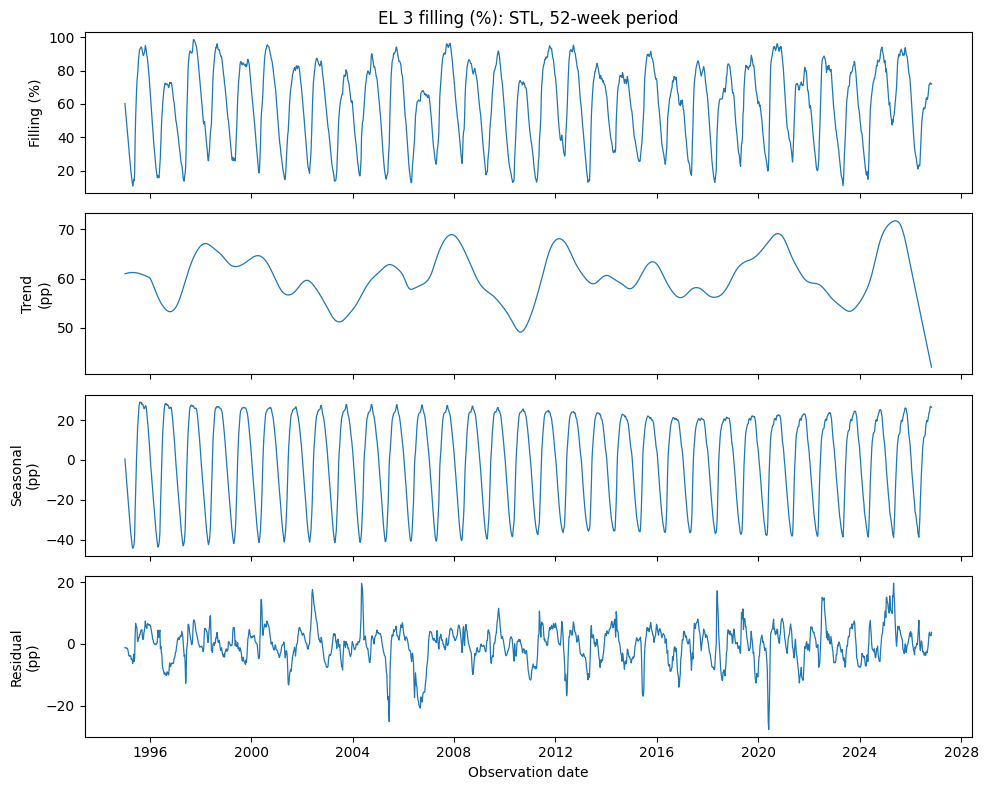

In [19]:
# Decompose all available weeks; this is not restricted to the weather year 2024.
components, stl_summary, fig = stl_analysis(weekly)
print(stl_summary)
plt.show()

In [20]:
# Reconstruction is an essential check for an additive decomposition.
assert components.index.equals(weekly.index)
assert np.allclose(components.trend + components.seasonal + components.residual, weekly)
changed_components, _, check_fig = stl_analysis(weekly, seasonal=21, trend=157, robust=False)
assert not np.allclose(changed_components.trend, components.trend)
assert not np.allclose(changed_components.seasonal, components.seasonal)
plt.close(check_fig)
print("PASS: additive reconstruction and response to STL smoothing/robust controls.")

PASS: additive reconstruction and response to STL smoothing/robust controls.


## Spectrogram: changing cycles over time

The spectrogram divides the same weekly history into overlapping Hann windows
and estimates the power spectral density (PSD) in each window. The default window
is **104 weeks**, with **52 weeks of overlap**. Each window is detrended by
subtracting its mean. Longer windows improve frequency resolution but blur when
changes happen. More overlap gives closer window centers; it does not increase
the underlying frequency resolution.

Sampling frequency is **one observation per week**. Frequencies are in
**cycles/week**, so an annual cycle is approximately **1/52 cycles/week** and the
Nyquist frequency is **0.5 cycles/week**. Time is plotted at the window-center
date. Density is in **pp²/(cycles/week)** and displayed in decibels relative to
one unit of that density. A stronger color indicates stronger variation at that
frequency, not a higher filling level. The 104-week default resolves frequencies
in steps of 1/104 cycles/week, placing an annual cycle at the second nonzero bin.

{'weeks': 1661, 'windows': 30, 'frequency_step': 0.009615384615384616, 'peak_period_weeks': 52.0}


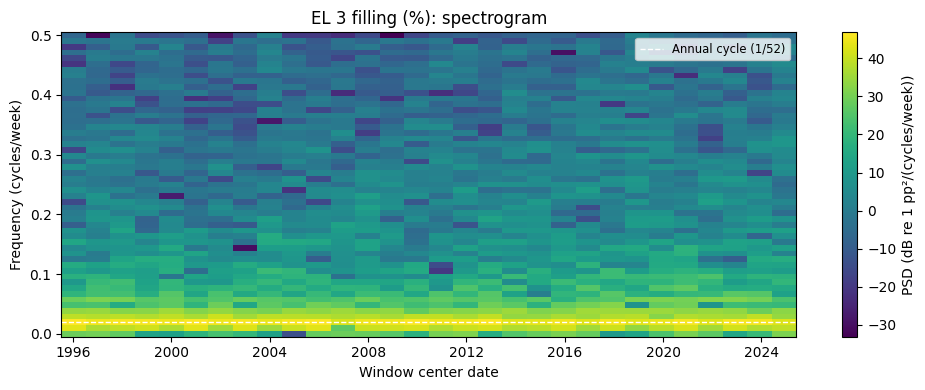

In [21]:
# Shared spectrum data has frequency rows and dated window-center columns.
spectrum, spectrum_summary, fig = filling_spectrogram(weekly)
print(spectrum_summary)
plt.show()

In [22]:
# Validate dimensions/units and recover a known annual signal in a controlled example.
assert np.isfinite(spectrum.to_numpy()).all() and (spectrum.to_numpy() >= 0).all()
assert spectrum.shape[0] == 104 // 2 + 1
assert np.isclose(spectrum.index.max(), 0.5)
assert np.isclose(np.diff(spectrum.index).mean(), 1 / 104)
assert (spectrum.columns.to_series().diff().dropna() == pd.Timedelta(weeks=52)).all()
changed_spectrum, _, check_fig = filling_spectrogram(weekly, window=156, overlap=104)
assert changed_spectrum.shape[0] != spectrum.shape[0]
plt.close(check_fig)
annual = pd.Series(
    50 + 10 * np.sin(2 * np.pi * np.arange(520) / 52),
    index=pd.date_range("2000-01-02", periods=520, freq="7D"), name="Known annual signal"
)
_, known_summary, check_fig = filling_spectrogram(annual)
assert np.isclose(known_summary["peak_period_weeks"], 52)
plt.close(check_fig)
print("PASS: nonnegative spectrum, time/frequency units, window controls, and known annual cycle.")

PASS: nonnegative spectrum, time/frequency units, window controls, and known annual cycle.



## AI-tool use

I used AI as support while working on the project. It helped me work through
ideas, write and adjust code for the APIs and databases, and add controls in
Streamlit. I also used it for help with small tests, simplifying repeated code,
and making the notebook text clearer. I am responsible for checking
the code and results, understanding the missing data, and making sure the final
submission meets the requirements.

## Compulsory-work log

Part 3 adds weather and data-quality analysis to the Norwegian reservoir dashboard. The Jupyter Notebook documents the calculations and checks, while Streamlit makes the main analyses interactive. Both use shared functions for downloading weather data and analysing reservoir filling, so the calculations remain consistent between the notebook and app.

The supplied shapefiles define five electricity areas, NO1 to NO5, and three grouped NVE regions, East, West, and North. The grouped regions approximate precipitation areas, not exact catchments. With seed 320, the notebook samples 1,000 candidate points inside each area and selects one per area. The eight coordinates are saved to CSV for the app.

The weather example uses hourly ERA5 precipitation and temperature for NO3 in 2024. Checks confirm complete UTC coverage, including February 29. Daily precipitation values are averages of hourly amounts, not daily totals. The notebook also distinguishes the sampled location from the ERA5 grid cell returned by the API.

A DCT filter separates precipitation into a slow baseline and faster fluctuations. Robust SPC limits flag unusually large deviations. An added notebook cell applies the same method to temperature, alongside the existing Local Outlier Factor analysis. These methods highlight dates for inspection without removing observations. Their results depend on the chosen settings, and a flag alone does not establish a data error.

STL separates the full weekly reservoir history into trend, seasonal variation, and residuals. A spectrogram shows how the strength of different cycles changes over time. Reconstruction checks and a known annual signal verify the calculations.

Streamlit provides area selectors and analysis controls, with cached weather downloads. The [public repository](https://github.com/dared22/ind320) contains the code, and the [Streamlit app](https://cklqlkatpe9mqyrnuch2ma.streamlit.app/) provides the online interface. Part 3 remains on a temporary branch for peer review. Deployment verification, the screencast, and submission remain to be completed.
